# Day 2 — Layout-Aware Document Understanding

**Module 4: Document Understanding**

**Goal:** Understand why layout matters and use a pretrained Donut model to turn a receipt image into structured data. Donut is an OCR-free document-understanding model: it processes the document image and generates a structured sequence.


### 1. Install dependencies

In [1]:
!pip -q install transformers sentencepiece datasets accelerate pillow matplotlib

### 2. Imports and runtime check

In [2]:
import json
import re
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from PIL import Image
from transformers import DonutProcessor, VisionEncoderDecoderModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cpu":
    print("Donut inference may be slow on CPU. A Colab GPU is recommended.")

Device: cuda


### 3. Load a sample receipt

We use the CORD receipt dataset, which is aligned with the Donut checkpoint used in this notebook. The dataset is downloaded from Hugging Face.

README.md:   0%|          | 0.00/27.0 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

data/train-00000-of-00004-b4aaeceff1d90e(…): reconstructing file:   0%|          |  0.00B /  490MB            

data/train-00000-of-00004-b4aaeceff1d90e(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-7dbbe248962764(…): reconstructing file:   0%|          |  0.00B /  441MB            

data/train-00001-of-00004-7dbbe248962764(…): downloading bytes:           |  0.00B            

... (7 outputs left out)

data/test-00000-of-00001-9c204eb3f4e1179(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/800 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/100 [00:00<?, ? examples/s]

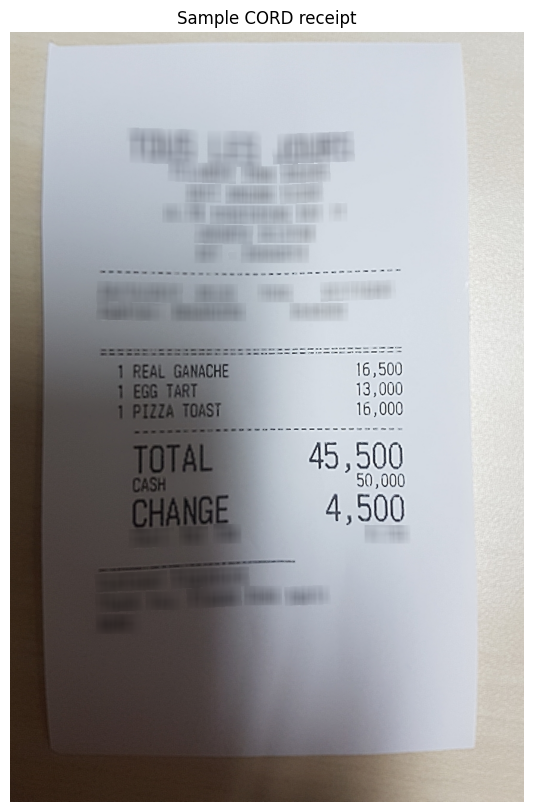

Image size: (864, 1296)


In [3]:
dataset = load_dataset("naver-clova-ix/cord-v2", split="validation")
sample = dataset[0]
image = sample["image"].convert("RGB")

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.title("Sample CORD receipt")
plt.show()

print("Image size:", image.size)

### Optional: upload own receipt


In [4]:
from google.colab import files

uploaded = files.upload()
image_file = next(iter(uploaded))
image = Image.open(image_file).convert("RGB")

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded receipt")
plt.show()

print("Image size:", image.size)

StopIteration: 

### 4. Why layout matters

Plain OCR may recognise `Invoice Number` and `INV-2048`, but it does not inherently know that the number belongs to that label. Layout provides clues such as proximity, alignment, reading order, and table structure.

**LayoutLMv3** combines:
- text tokens,
- 2D bounding boxes for those tokens,
- visual information from the document image.

It is used for tasks such as form understanding and token-level entity extraction. A base checkpoint is not automatically an invoice extractor: a task-specific fine-tuned checkpoint or training is needed.

### 5. Donut: image-to-structured-output

Donut (Document Understanding Transformer) is an OCR-free approach. It processes the document image and generates a structured token sequence without requiring a separate OCR engine first.

We use `naver-clova-ix/donut-base-finetuned-cord-v2`, a checkpoint fine-tuned for receipt parsing.

In [5]:
model_name = "naver-clova-ix/donut-base-finetuned-cord-v2"

processor = DonutProcessor.from_pretrained(model_name)
model = VisionEncoderDecoderModel.from_pretrained(model_name)
model.to(device)
model.eval()

print("Loaded:", model_name)

preprocessor_config.json:   0%|          | 0.00/362 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.02M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/1.52k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/335 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  806MB            

model.safetensors: downloading bytes:           |  0.00B            

Loaded: naver-clova-ix/donut-base-finetuned-cord-v2


### 6. Prepare the image and task prompt

In [6]:
pixel_values = processor(image, return_tensors="pt").pixel_values.to(device)

task_prompt = "<s_cord-v2>"
decoder_input_ids = processor.tokenizer(
    task_prompt, add_special_tokens=False, return_tensors="pt"
).input_ids.to(device)

print("Pixel tensor shape:", tuple(pixel_values.shape))
print("Prompt IDs shape:", tuple(decoder_input_ids.shape))

Pixel tensor shape: (1, 3, 1280, 960)
Prompt IDs shape: (1, 1)


### 7. Generate a structured prediction

This may take a few minutes, especially on CPU.

In [7]:
with torch.no_grad():
    outputs = model.generate(
        pixel_values,
        decoder_input_ids=decoder_input_ids,
        max_length=768,
        early_stopping=True,
        pad_token_id=processor.tokenizer.pad_token_id,
        eos_token_id=processor.tokenizer.eos_token_id,
        use_cache=True,
        num_beams=1,
        bad_words_ids=[[processor.tokenizer.unk_token_id]],
        return_dict_in_generate=True,
    )

sequence = processor.batch_decode(outputs.sequences)[0]
sequence = sequence.replace(processor.tokenizer.eos_token, "")
sequence = sequence.replace(processor.tokenizer.pad_token, "")
sequence = re.sub(r"<.*?>", "", sequence, count=1).strip()

print(sequence[:3000])

[transformers] The following generation flags are not valid and may be ignored: ['early_stopping']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


<s_menu><s_nm> REAL GANACHE</s_nm><s_cnt> 1</s_cnt><s_price> 16,500</s_price><sep/><s_nm> EGG TART</s_nm><s_cnt> 1</s_cnt><s_price> 13,000</s_price><sep/><s_nm> PIZZA TOAST</s_nm><s_cnt> 1</s_cnt><s_price> 16,000</s_price></s_menu><s_total><s_total_price> 45,500</s_total_price><s_cashprice> 50,000</s_cashprice><s_changeprice> 4,500</s_changeprice></s_total>


### 8. Convert the generated sequence into JSON

Donut's tokenizer provides `token2json` to convert its structured special-token representation into Python dictionaries and lists. Inspect the result rather than assuming every field is correct.

In [8]:
try:
    parsed = processor.tokenizer.token2json(sequence)
    print(json.dumps(parsed, indent=2, ensure_ascii=False))
except Exception as error:
    parsed = None
    print("Automatic parsing failed:", type(error).__name__, error)
    print("Inspect the raw sequence printed in the previous cell.")

Automatic parsing failed: AttributeError TokenizersBackend has no attribute token2json
Inspect the raw sequence printed in the previous cell.


### 9. Inspect the extracted structure

In [9]:
if isinstance(parsed, dict):
    print("Top-level keys:", list(parsed.keys()))
    print("JSON serialisation check:", isinstance(json.loads(json.dumps(parsed)), dict))
else:
    print("No parsed dictionary available. Review the raw model sequence.")

No parsed dictionary available. Review the raw model sequence.


### 10. Compare LayoutLMv3 and Donut

| Aspect | LayoutLMv3 | Donut |
|---|---|---|
| Typical input | OCR text, bounding boxes, and image | Document image |
| Separate OCR stage | Usually yes | No external OCR stage required |
| Layout information | Explicit token boxes plus image | Learned from the image |
| Output | Depends on fine-tuned task head | Generated structured sequence |
| Main consideration | Needs OCR words/boxes and task-specific fine-tuning | Generation can be slow; output needs validation |

Neither approach is always better. The choice depends on document type, language, accuracy, compute, and deployment needs.

### 11. Save the raw output and JSON

In [10]:
from pathlib import Path

output_dir = Path("module4_day2_outputs")
output_dir.mkdir(exist_ok=True)

(output_dir / "donut_raw_output.txt").write_text(sequence, encoding="utf-8")

if parsed is not None:
    (output_dir / "donut_extracted.json").write_text(
        json.dumps(parsed, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

print("Saved files:")
for file_path in sorted(output_dir.iterdir()):
    print(file_path)

Saved files:
module4_day2_outputs/donut_raw_output.txt
